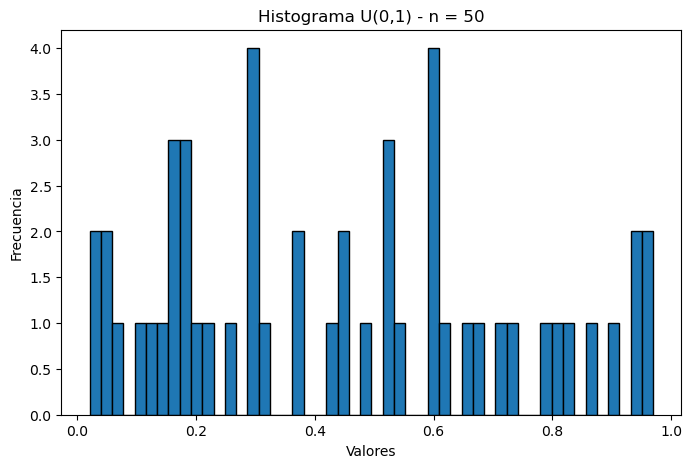

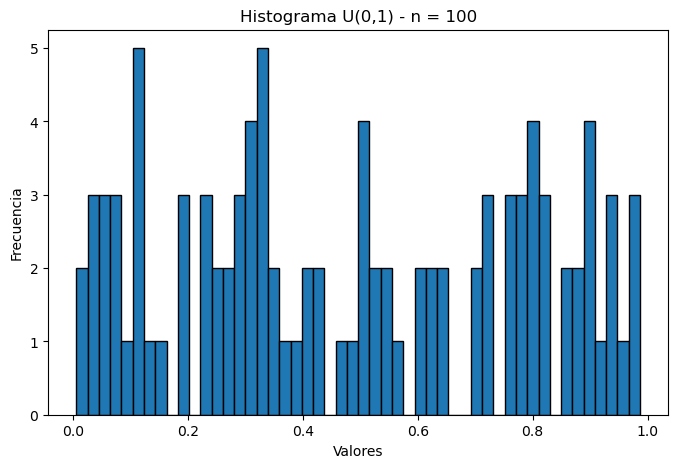

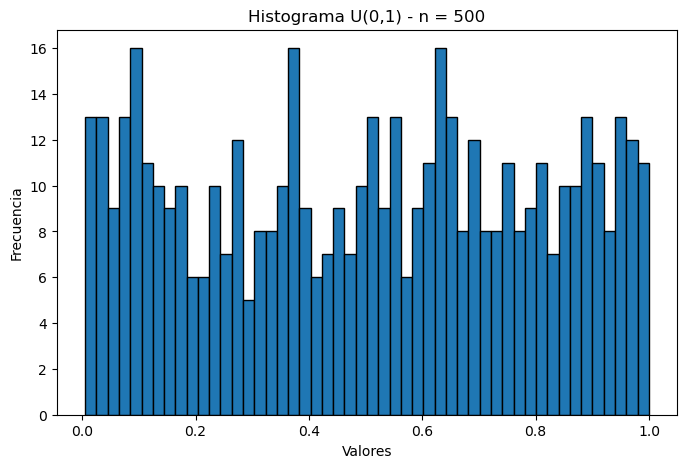

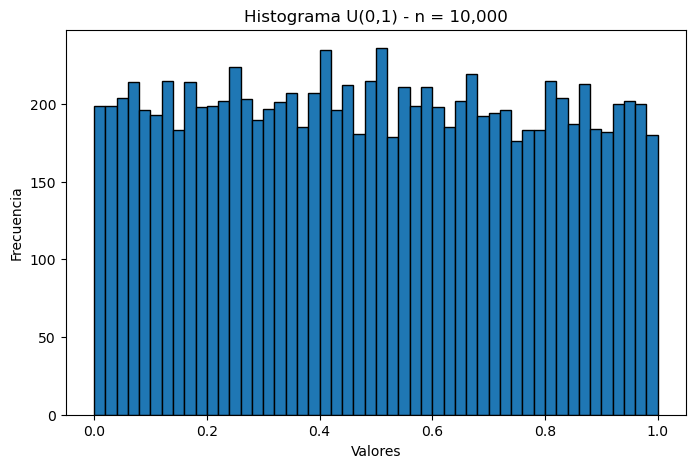

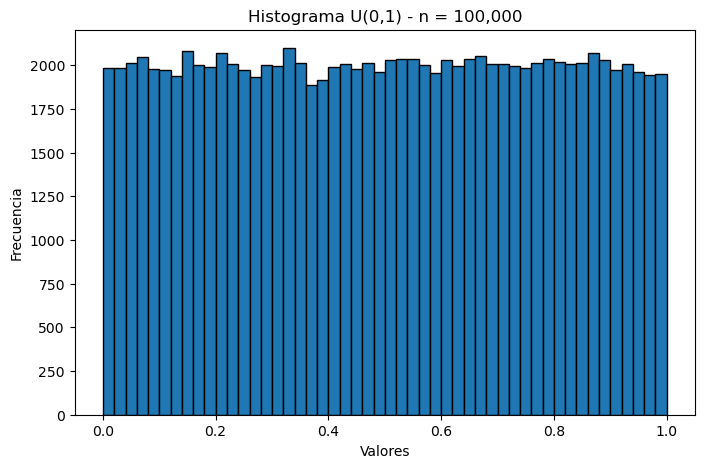

In [6]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = [50, 100, 500, 10000, 100000]

for i in n:
    m = np.random.uniform(0, 1, i)

    plt.figure(figsize=(8, 5))
    plt.hist(m, bins=50, edgecolor='black')

    plt.title(f'Histograma U(0,1) - n = {i:,}')
    plt.xlabel('Valores')
    plt.ylabel('Frecuencia')

    plt.show()

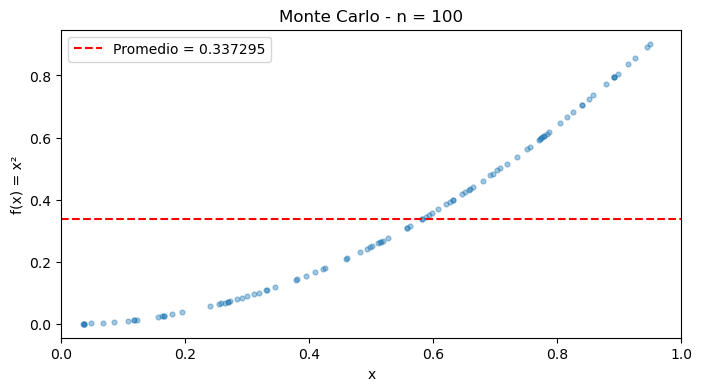

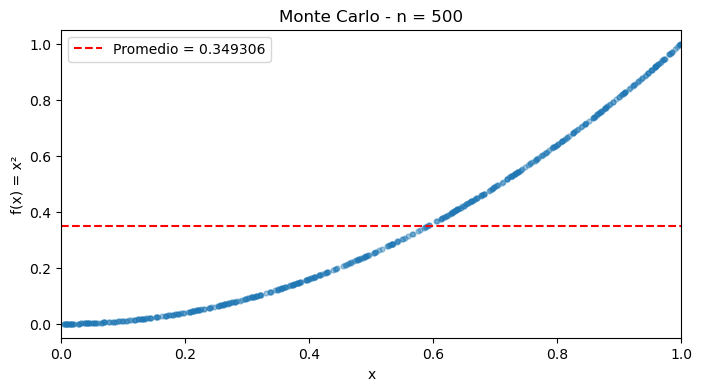

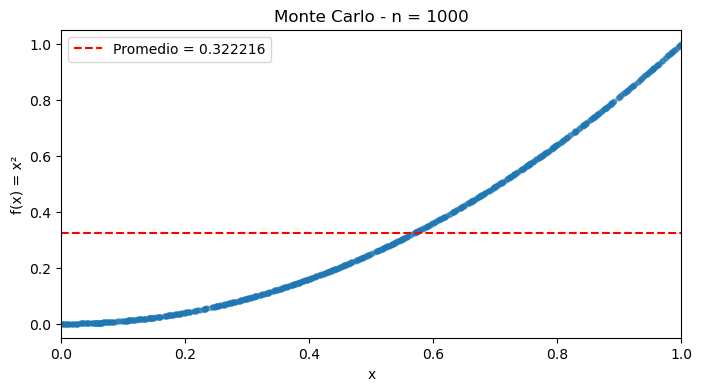

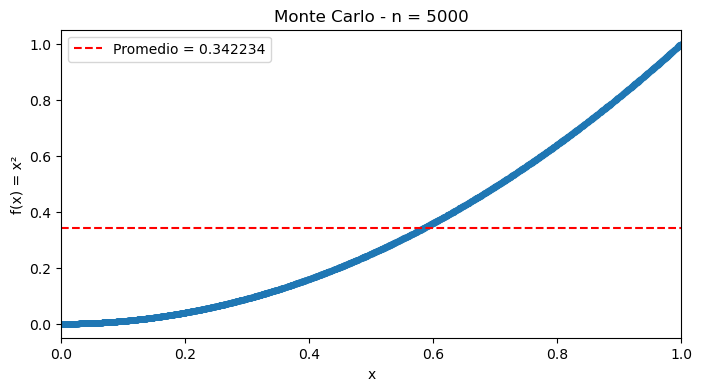

Valor exacto: 0.3333333333333333


,Muestras,f(c)(b-a),Error
0,100,0.337295,0.003962
1,500,0.349306,0.015973
2,1000,0.322216,0.011118
3,5000,0.342234,0.008900


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(20)

a = 0
b = 1
n = [100, 500, 1000, 5000]

valor_exacto = 1/3
resultados = []

for i in n:

    # Generar muestras aleatorias
    c = np.random.uniform(a, b, i)

    # Evaluar la función
    f = c**2

    # Calcular el promedio
    promedio = np.mean(f)

    # Aproximar la integral
    integral = promedio * (b - a)

    # Calcular el error
    error = abs(valor_exacto - integral)

    resultados.append([i, integral, error])

    # Gráfica
    plt.figure(figsize=(8, 4))
    plt.scatter(c, f, alpha=0.4, s=12)
    plt.axhline(promedio, color='red', linestyle='--',
                label=f'Promedio = {promedio:.6f}')

    plt.title(f'Monte Carlo - n = {i}')
    plt.xlabel('x')
    plt.ylabel('f(x) = x²')
    plt.xlim(a, b)
    plt.legend()
    plt.show()

# Tabla de resultados
tabla = pd.DataFrame(resultados, columns=[
    'Muestras',
    'f(c)(b-a)',
    'Error'
])

print('Valor exacto:', valor_exacto)
display(tabla.round(6))

/opt/anaconda3/lib/python3.13/site-packages/scipy/stats/_qmc.py:993: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  sample = self._random(n, workers=workers)


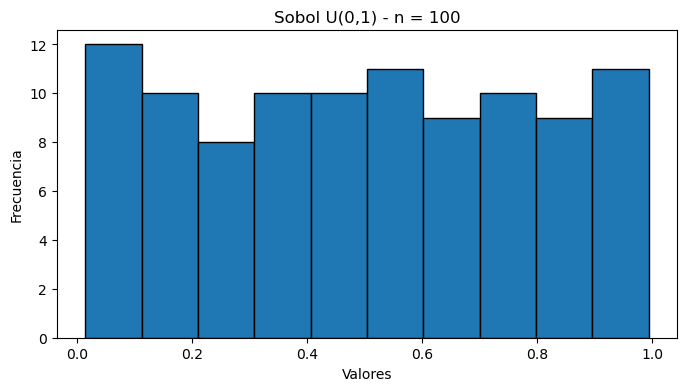

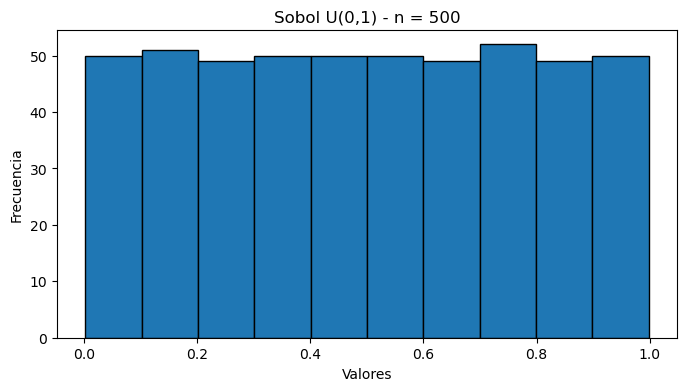

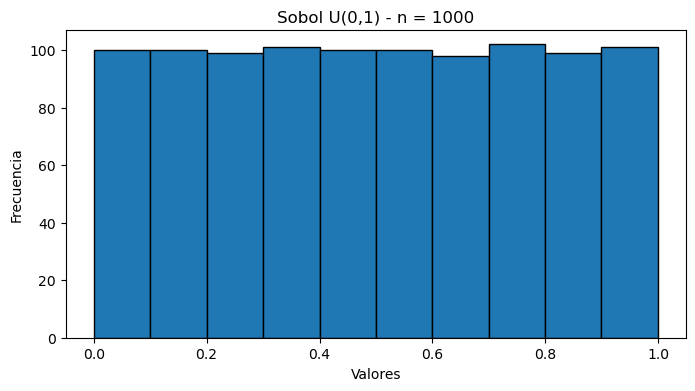

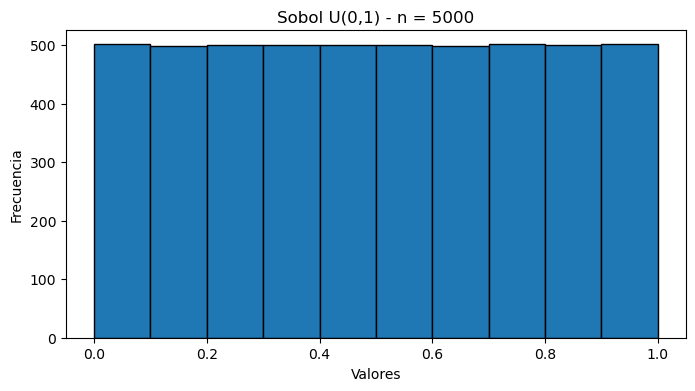

Valor exacto: 0.3333333333333333


,Muestras,Promedio f(c),Integral Sobol,Error
0,100,0.334597,0.334597,0.001264
1,500,0.333159,0.333159,0.000174
2,1000,0.333556,0.333556,0.000223
3,5000,0.333376,0.333376,0.000043


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import qmc

n = [100, 500, 1000, 5000]

a = 0
b = 1
valor_exacto = 1/3

resultados = []

for i in n:

    # Generar secuencia Sobol
    sobol = qmc.Sobol(d=1, scramble=True, seed=20)
    u = sobol.random(n=i).flatten()

    # Evaluar la función
    f = u**2

    # Calcular el promedio
    promedio = np.mean(f)

    # Aproximar la integral
    integral = promedio * (b - a)

    # Calcular el error absoluto
    error = abs(valor_exacto - integral)

    resultados.append([i, promedio, integral, error])

    # Histograma
    plt.figure(figsize=(8, 4))
    plt.hist(u, bins=10, edgecolor='black')
    plt.title(f'Sobol U(0,1) - n = {i}')
    plt.xlabel('Valores')
    plt.ylabel('Frecuencia')
    plt.show()

# Tabla de resultados
tabla = pd.DataFrame(resultados, columns=[
    'Muestras',
    'Promedio f(c)',
    'Integral Sobol',
    'Error'
])

print('Valor exacto:', valor_exacto)
display(tabla.round(6))

In [12]:
import numpy as np
import pandas as pd
from scipy.stats import qmc

np.random.seed(20)

n = [100, 500, 1000, 5000]

a = 0
b = 1
valor_exacto = 1/3

resultados = []

for i in n:

    # Monte Carlo
    mc = np.random.uniform(a, b, i)
    integral_mc = np.mean(mc**2) * (b-a)
    error_mc = abs(valor_exacto - integral_mc)

    # Cuasi-Monte Carlo (Sobol)
    sobol = qmc.Sobol(d=1, scramble=True, seed=20)
    u = sobol.random(n=i).flatten()

    integral_qmc = np.mean(u**2) * (b-a)
    error_qmc = abs(valor_exacto - integral_qmc)

    resultados.append([
        i, integral_mc, integral_qmc,
        error_mc, error_qmc
    ])

tabla = pd.DataFrame(resultados, columns=[
    'Muestras',
    'Integral MC',
    'Integral QMC',
    'Error MC',
    'Error QMC'
])

print('Valor exacto:', valor_exacto)
display(tabla.round(6))

Valor exacto: 0.3333333333333333


/opt/anaconda3/lib/python3.13/site-packages/scipy/stats/_qmc.py:993: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  sample = self._random(n, workers=workers)


,Muestras,Integral MC,Integral QMC,Error MC,Error QMC
0,100,0.337295,0.334597,0.003962,0.001264
1,500,0.349306,0.333159,0.015973,0.000174
2,1000,0.322216,0.333556,0.011118,0.000223
3,5000,0.342234,0.333376,0.008900,0.000043
